# Porting the diagnostics to HadCM3

`x4c.Timeseries` reads CESM output by default, but the same class can read other
models' output when given a **model spec**: a translation table from CESM-style
variable names to the model's own (`vn_dict`), a filename template that explains
the folder structure (`path_pattern`), and a mapping of dimension names (`dim_map`).
Once loaded, variables carry the same metadata as CESM output, so `.x.gm`,
`.x.plot`, `case.calc` and the derived variables in `x4c.diags` work unchanged.

This notebook runs on the iHadCM3 climatologies under
`/glade/campaign/univ/umcp0052/data/iHadCM3/Data`, using the built-in `hadcm3` spec.

In [1]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import x4c

x4c.set_style('journal')

# after set_style: it resets rcParams from matplotlibrc defaults, which includes the
# backend, so assert the inline backend last or figures are never captured
%matplotlib inline

root = '/glade/campaign/univ/umcp0052/data/iHadCM3/Data'

## The folder structure

Each experiment is a directory named by its experiment ID. Inside, every file is a
multi-year climatology for one **period** (`jan` ... `dec`, `djf`/`mam`/`jja`/`son`,
`ann`) and one file group, plus three boundary-condition files without a period:

```
tfdul/tfdul.<period>_precip_temp_shum_msl_surf_data.nc
tfdul/tfdul.<period>_isotope_and_atmos_clomun_data.nc
tfdul/tfdul.<period>_SST_Seaice_data.nc
tfdul/tfdul.qrparm.mask.nc   tfdul.qrparm.orog.nc   tfdul.qrfrac.type.nc
```

The spec describes this with two filename templates. The file group plays the role
of CESM's history stream, so it is called `hstr`.

In [2]:
spec = x4c.models.get_spec('hadcm3')
print('path patterns:', spec.path_patterns)
print('models       :', x4c.models.list_models())
expts = x4c.models.list_cases(root, 'hadcm3')
print(f'{len(expts)} experiments:', expts)

path patterns: ['{case}.{period}_{hstr}.nc', '{case}.{hstr}.nc']
models       : ['hadcm3']
25 experiments: ['tevef', 'tevew', 'tfclb', 'tfcld', 'tfclf', 'tfdua', 'tfdub', 'tfduc', 'tfdud', 'tfdue', 'tfduf', 'tfdug', 'tfduh', 'tfdui', 'tfduj', 'tfduk', 'tfdul', 'tfdum', 'tfdun', 'tfduo', 'tfdup', 'tfduq', 'tfdur', 'xqeqb', 'xqeqd']


## Opening a case

The only change from a CESM case is `model='hadcm3'`. The stray file
`tfdul_isotope_and_atmos_clomun_data.nc` (no period in its name; a copy of the SON
file) matches no template and is skipped with a warning.

In [3]:
case = x4c.Timeseries(f'{root}/tfdul', model='hadcm3')

>>> case.root_dir: /glade/campaign/univ/umcp0052/data/iHadCM3/Data/tfdul
>>> case.model: hadcm3
>>> case.path_pattern: ['{case}.{period}_{hstr}.nc', '{case}.{hstr}.nc']
>>> case.casename: tfdul
>>> 54 files indexed; case.vns[hstr] created for hstr: ['SST_Seaice_data', 'isotope_and_atmos_clomun_data', 'precip_temp_shum_msl_surf_data', 'qrfrac.type', 'qrparm.mask', 'qrparm.orog']
>>> periods: ['jan', 'feb', 'mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec', 'djf', 'mam', 'jja', 'son', 'ann']
>>> Skipping file matching no path pattern: tfdul_isotope_and_atmos_clomun_data.nc


`case.info()` lists the raw variable names in each file group and the CESM-style
names the spec can serve for this case.

In [4]:
case.info()

>>> hadcm3 case `tfdul`
  hstr `SST_Seaice_data`: ['iceconc_mm_uo', 'temp_mm_dpth']
  hstr `isotope_and_atmos_clomun_data`: ['QCL_mm', 'ht_mm_p', 'icedepth_mm_srf', 'icedepth_mm_srf_1', 'omega_mm_p', 'q_mm_hyb', 'q_mm_hyb_1', 'q_mm_p', 'rh_mm_p', 'snowdepth_mm_srf', 'snowdepth_mm_srf_1', 'temp_mm_p', 'temp_mm_srf', 'temp_mm_srf_1', 'u_mm_p', 'uq_mm_p', 'v_mm_p', 'vq_mm_p']
  hstr `precip_temp_shum_msl_surf_data`: ['lh_mm_srf', 'p_mm_msl', 'p_mm_srf', 'precip_mm_srf', 'q_mm_1_5m', 'temp_mm_srf']
  hstr `qrfrac.type`: ['field1391']
  hstr `qrparm.mask`: ['field700', 'lsm']
  hstr `qrparm.orog`: ['field150', 'field152', 'field153', 'field154', 'field174', 'field175', 'ht']
  names from vn_dict available: ['CLDLIQ', 'ICEFRAC', 'LANDFRAC', 'LHFLX', 'OMEGA', 'OROG', 'PHIS', 'PRECT', 'PS', 'PSL', 'Q', 'QREFHT', 'RELHUM', 'SST', 'T', 'TS', 'U', 'UQ', 'V', 'VQ', 'Z3']

  Untranslated isotope tracer fields (load them by raw name) -- their meaning is
  inferred from ratios, not from documentation

## The translation table

`case.vn_dict` maps each CESM-style name to its source variable, file group, and an
optional linear unit conversion. HadCM3 precipitation, for example, is a rate in
kg m⁻² s⁻¹ (the file mislabels it as kg m⁻²); `PRECT` converts it to CESM's m/s.

In [5]:
import pandas as pd
pd.DataFrame(
    [(k, v.src, v.hstr, v.scale, v.offset, v.units, v.comp) for k, v in case.vn_dict.items()],
    columns=['vn', 'src', 'hstr', 'scale', 'offset', 'units', 'comp'],
).set_index('vn')

,src,hstr,scale,offset,units,comp
vn,,,,,,
TS,temp_mm_srf,precip_temp_shum_msl_surf_data,1.00000,0.0,K,atm
PRECT,precip_mm_srf,precip_temp_shum_msl_surf_data,0.00100,0.0,m/s,atm
PSL,p_mm_msl,precip_temp_shum_msl_surf_data,1.00000,0.0,Pa,atm
PS,p_mm_srf,precip_temp_shum_msl_surf_data,1.00000,0.0,Pa,atm
QREFHT,q_mm_1_5m,precip_temp_shum_msl_surf_data,1.00000,0.0,kg/kg,atm
LHFLX,lh_mm_srf,precip_temp_shum_msl_surf_data,1.00000,0.0,W/m2,atm
U,u_mm_p,isotope_and_atmos_clomun_data,1.00000,0.0,m/s,atm
V,v_mm_p,isotope_and_atmos_clomun_data,1.00000,0.0,m/s,atm
OMEGA,omega_mm_p,isotope_and_atmos_clomun_data,1.00000,0.0,Pa/s,atm


## Loading variables

The files are climatologies, so instead of a `timespan`, `load` takes a `period`:
a single tag, a list of tags (stacked along a `period` dim), or `'climo'` (the 12
monthly files stacked along `time` = 1..12, the same shape `.x.climo` gives for
CESM output).

In [6]:
case.load('TS', period='ann')
ts = case.ds['TS'].x.da
print(dict(ts.sizes), ts.attrs['units'], '| source:', ts.attrs['src_name'])
print(f'GMST: {float(ts.x.gm) - 273.15:.2f} °C  (NH {float(ts.x.nhm) - 273.15:.2f}, SH {float(ts.x.shm) - 273.15:.2f})')

>>> case.ds["TS"] created
{'lat': 73, 'lon': 96} K | source: temp_mm_srf
GMST: 17.39 °C  (NH 16.14, SH 18.14)


>>> case.ds["TS"] will be reloaded due to a different period/hstr.


>>> case.ds["TS"] created
mean of the monthly climatology: 17.392


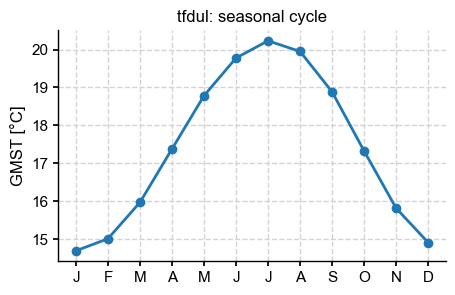

In [7]:
case.load('TS', period='climo')
gm = case.ds['TS'].x.da.x.gm - 273.15

fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(gm.time, gm, marker='o')
ax.set_xticks(range(1, 13), list('JFMAMJJASOND'))
ax.set_ylabel('GMST [°C]')
ax.set_title(f'{case.casename}: seasonal cycle');
print('mean of the monthly climatology:', float(gm.mean()).__round__(3))

In [8]:
case.load('PRECT', period=['djf', 'jja'])
pr = case.ds['PRECT'].x.da * 8.64e7   # m/s -> mm/day
pr.attrs['units'] = 'mm/day'
print('global mean precipitation [mm/day]:', {str(p): round(float(v), 3) for p, v in zip(pr.period.values, pr.x.gm.values)})

>>> case.ds["PRECT"] created
global mean precipitation [mm/day]: {'djf': 3.039, 'jja': 3.182}


## Maps

The experiments use paleogeographies, so the modern Cartopy coastlines would be
wrong. Passing a sea-surface variable as `ssv` draws the coastlines from its land
mask instead.

>>> case.ds["SST"] created


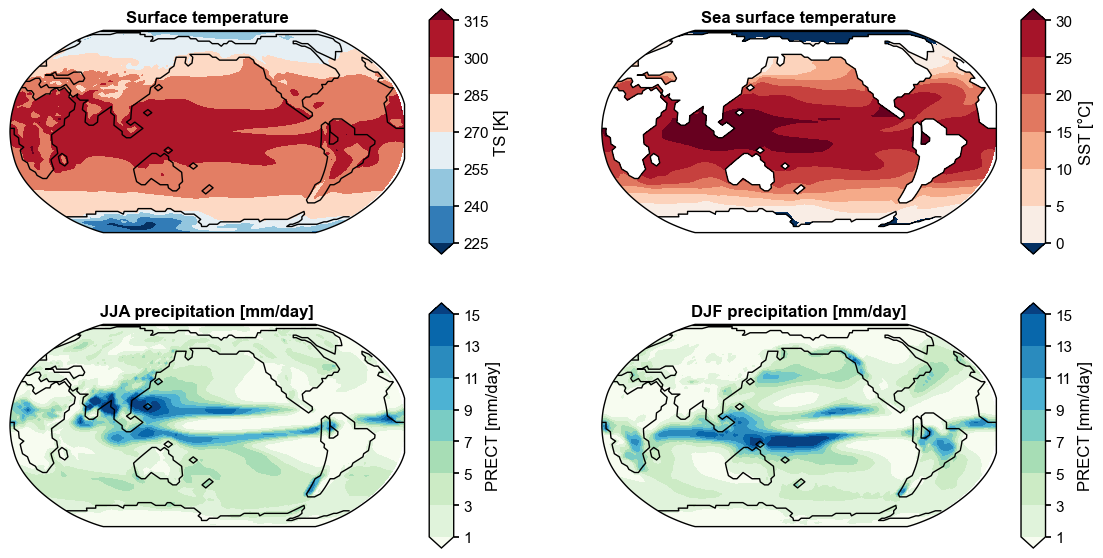

In [9]:
case.load('SST', period='ann')
sst = case.ds['SST'].x.da

fig, axs = plt.subplots(2, 2, figsize=(14, 7), subplot_kw={'projection': ccrs.Robinson(central_longitude=180)})
axs = axs.ravel()
ts.x.plot(ax=axs[0], ssv=sst)
sst.x.plot(ax=axs[1])
pr.sel(period='jja').x.plot(ax=axs[2], ssv=sst, title='JJA precipitation [mm/day]', cmap='GnBu', levels=np.arange(1, 17, 2))
pr.sel(period='djf').x.plot(ax=axs[3], ssv=sst, title='DJF precipitation [mm/day]', cmap='GnBu', levels=np.arange(1, 17, 2));

## Pressure-level fields

The 3-D atmosphere fields are already on 17 pressure levels (dim `plev`, hPa), so
no `get_plev` step is needed. HadCM3 uses an Arakawa B-grid: winds sit on a
96 × 72 grid offset from the 96 × 73 temperature grid. Each loaded variable keeps
its native grid, with an area weight that matches it.

>>> case.ds["U"] created
>>> case.ds["T"] created
U: {'plev': 17, 'lat': 72, 'lon': 96} | T: {'plev': 17, 'lat': 73, 'lon': 96}


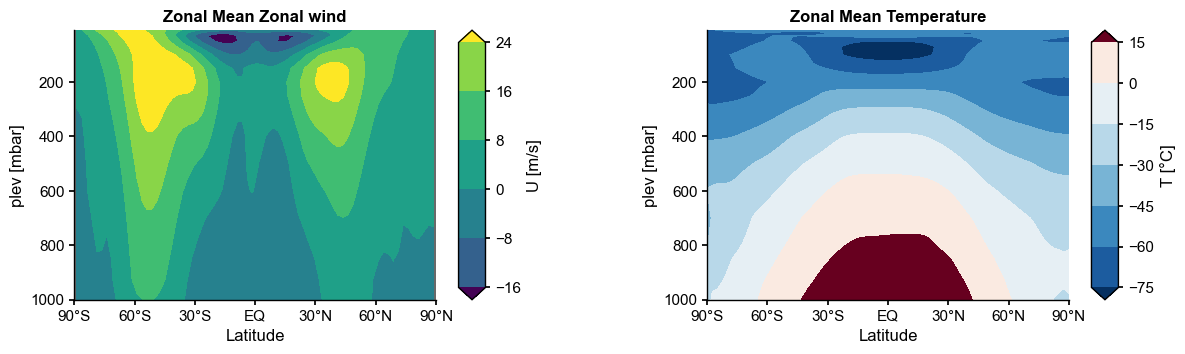

In [10]:
case.load('U', period='ann')
case.load('T', period='ann')
print('U:', dict(case.ds['U'].x.da.sizes), '| T:', dict(case.ds['T'].x.da.sizes))

t_zm = case.ds['T'].x.da.x.zm - 273.15
t_zm.attrs['units'] = '°C'

fig, axs = plt.subplots(1, 2, figsize=(14, 3.5), gridspec_kw={'wspace': 0.4})
case.ds['U'].x.da.x.zm.x.plot(ax=axs[0])
t_zm.x.plot(ax=axs[1], title='Zonal Mean Temperature')
for ax in axs: ax.invert_yaxis()

## Derived variables

`load` checks the registry in `x4c.diags` for names that are not in the files. A
name the model writes directly wins: HadCM3 has `PRECT`, so the CESM recipe
(`PRECC + PRECL`) is not used. Recipes built from names the spec translates do
run. `LST` is `TS` masked by `LANDFRAC > 0.5`, two variables that come from
different HadCM3 files.

>>> LST is a supported derived variable.
>>> case.ds["TS"] will be reloaded due to a different period/hstr.
>>> case.ds["TS"] created
>>> case.ds["LANDFRAC"] created
>>> case.ds["LST"] created
JJA global-mean land surface temperature: 18.60 °C


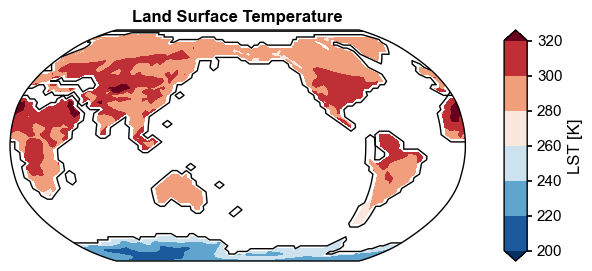

In [11]:
case.load('LST', period='jja')
lst = case.ds['LST']
print(f'JJA global-mean land surface temperature: {float(lst.x.gm) - 273.15:.2f} °C')
lst.x.plot(ssv=sst, cyclic=True);

## Spells

`case.calc` works too. Leave the annualization field empty (`vn::sa_method`),
since the data are already time means, and pass `period` through.

[14.69 15.01 15.97 17.38 18.78 19.78 20.23 19.95 18.88 17.32 15.81 14.91]


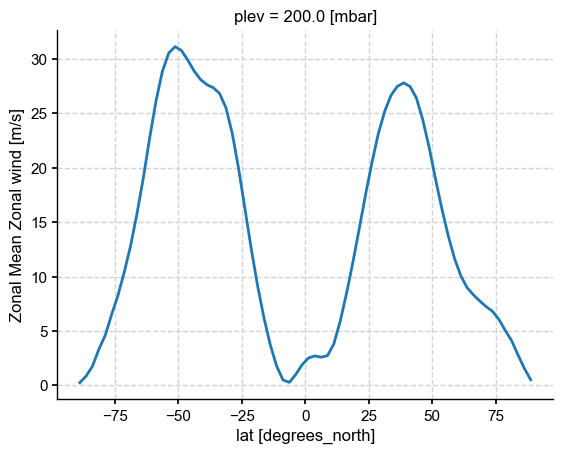

In [12]:
print(case.calc('GMST ~ TS::gm', period='climo', verbose=False).values.round(2))
case.calc('U200 ~ U.sel(plev=200)::zm', period='ann', verbose=False).plot();

## Raw names and `hstr`

Any raw source name can be loaded as well. When a name exists in more than one
file group, `hstr` picks the group. The isotope tracer fields are deliberately left
out of the translation table, because their meaning has not been confirmed yet
(see `spec.notes` above).

In [13]:
try:
    case.load('temp_mm_srf', period='ann')
except ValueError as e:
    print('ValueError:', e)

case.load('q_mm_hyb', period='ann', hstr='isotope_and_atmos_clomun_data')
print(dict(case.ds['q_mm_hyb'].x.da.sizes))

ValueError: `temp_mm_srf` exists in several hstr ['isotope_and_atmos_clomun_data', 'precip_temp_shum_msl_surf_data']; pass `hstr=`.
>>> case.ds["q_mm_hyb"] created
{'lev': 19, 'lat': 73, 'lon': 96}


## Extending the translation table

`vn_dict` entries are merged over the model's own table, so names can be added or
redefined for one case without touching the built-in spec. A value is a source
name, or a dict with `src`, `hstr`, `scale`, `offset`, `units`, `long_name`, `comp`
and `isel`.

In [14]:
case2 = x4c.Timeseries(
    f'{root}/tfdul', model='hadcm3',
    vn_dict={
        'TSC': {'src': 'temp_mm_srf', 'hstr': 'precip_temp_shum_msl_surf_data',
                'offset': -273.15, 'units': '°C', 'long_name': 'Surface temperature'},
        'PRECT_mmday': {'src': 'precip_mm_srf', 'scale': 86400, 'units': 'mm/day'},
    },
)
case2.load('TSC', period='ann', verbose=False)
case2.load('PRECT_mmday', period='ann', verbose=False)
print(f"TSC gm = {float(case2.ds['TSC'].x.da.x.gm):.2f} °C, PRECT_mmday gm = {float(case2.ds['PRECT_mmday'].x.da.x.gm):.3f} mm/day")

>>> case.root_dir: /glade/campaign/univ/umcp0052/data/iHadCM3/Data/tfdul
>>> case.model: hadcm3
>>> case.path_pattern: ['{case}.{period}_{hstr}.nc', '{case}.{hstr}.nc']
>>> case.casename: tfdul
>>> 54 files indexed; case.vns[hstr] created for hstr: ['SST_Seaice_data', 'isotope_and_atmos_clomun_data', 'precip_temp_shum_msl_surf_data', 'qrfrac.type', 'qrparm.mask', 'qrparm.orog']
>>> periods: ['jan', 'feb', 'mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec', 'djf', 'mam', 'jja', 'son', 'ann']
>>> Skipping file matching no path pattern: tfdul_isotope_and_atmos_clomun_data.nc
TSC gm = 17.39 °C, PRECT_mmday gm = 3.091 mm/day


## Across experiments

Because every case is read the same way, comparing all 25 experiments is a loop.
Five of them hold only the boundary-condition files; `LANDFRAC` still loads for
those.

In [15]:
import contextlib, io

rows = []
for expt in expts:
    with contextlib.redirect_stdout(io.StringIO()):   # silence the per-case index banner
        c = x4c.Timeseries(f'{root}/{expt}', model='hadcm3')
    row = {'expt': expt}
    c.load('LANDFRAC', verbose=False)
    row['land fraction'] = float(c.ds['LANDFRAC'].x.da.x.gm)
    if c.reader.has('TS'):
        c.load('TS', period='ann', verbose=False)
        c.load('PRECT', period='ann', verbose=False)
        row['GMST [°C]'] = float(c.ds['TS'].x.da.x.gm) - 273.15
        row['precip [mm/day]'] = float(c.ds['PRECT'].x.da.x.gm) * 8.64e7
    rows.append(row)

df = pd.DataFrame(rows).set_index('expt')
df.round(3)

,land fraction,GMST [°C],precip [mm/day]
expt,,,
tevef,0.271,22.287,3.360
tevew,0.271,22.993,3.363
tfclb,0.285,22.811,3.316
tfcld,0.288,22.212,3.251
tfclf,0.288,22.538,3.283
tfdua,0.270,22.270,3.382
tfdub,0.274,23.026,3.442
tfduc,0.275,NaN,NaN
tfdud,0.271,24.161,3.528


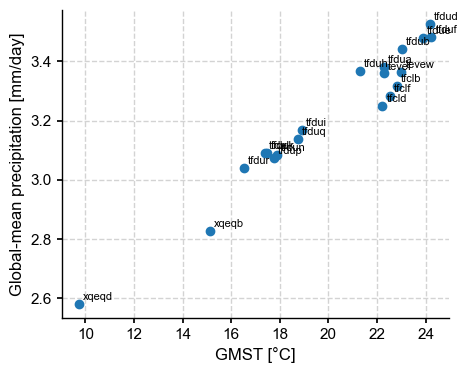

In [16]:
d = df.dropna()
fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(d['GMST [°C]'], d['precip [mm/day]'])
for name, r in d.iterrows():
    ax.annotate(name, (r['GMST [°C]'], r['precip [mm/day]']), fontsize=8, xytext=(3, 3), textcoords='offset points')
ax.set_xlabel('GMST [°C]')
ax.set_ylabel('Global-mean precipitation [mm/day]');

## Adding another model

Another model needs only a spec, either inline as `Timeseries` arguments or
registered once with `x4c.models.register(x4c.models.ModelSpec(...))` and then
selected by `model=`. For example, a CMIP-style layout with one variable per file:

```python
case = x4c.Timeseries(
    '/path/to/run1',
    path_pattern='{vn}_Amon_{case}_{timespan}.nc',
    vn_dict={'TREFHT': 'tas', 'PRECT': {'src': 'pr', 'scale': 1e-3, 'units': 'm/s'}},
    dim_map={'latitude': 'lat', 'longitude': 'lon'},
)
case.load('TREFHT')   # all timespans concatenated along time
```

## Caveats

**About the iHadCM3 data**

- **Climatologies, not time series.** Every file is a multi-year mean with one time
  step. Its time units (e.g. `days since 13850-12-00`) are not valid CF, so times are not
  decoded and the time dim is dropped. Anything that needs a real time axis, such as
  `.x.annualize()`, the `ann` field of a spell, or `.x.anom`, does not apply here. Use
  `period=` instead.
- **Isotope tracers are untranslated.** The stash-coded fields in the isotope file
  (`q_mm_hyb`, `q_mm_hyb_1`, the `snowdepth_mm_srf*` / `icedepth_mm_srf*` pairs) carry
  CF and PCMDI names that the conversion tool (xconv) guessed from the default
  STASHmaster; ignore them. Their meaning was inferred only from value ratios (see
  `spec.notes`), so confirm it with the data provider before use. In that file,
  `temp_mm_srf` and `temp_mm_srf_1` are not surface temperature. No precipitation
  isotopes or hybrid-level H₂¹⁶O are present, so δ¹⁸O of precipitation cannot be
  computed from these files alone.
- **Incomplete experiments.** `tfduc`, `tfdug`, `tfduj`, `tfdum` and `tfduo` hold only the
  boundary-condition files. `<expid>_isotope_and_atmos_clomun_data.nc` (no period) is a
  copy of the SON file and is skipped.
- **Native B-grid.** Winds and their transports (`U`, `V`, `OMEGA`, `Q`, `UQ`, `VQ`) are on
  the 96 × 72 velocity grid; temperature-point fields are on 96 × 73. Arithmetic that mixes
  the two grids (e.g. `U * T`) needs one of them interpolated first.
- **`SST`** is the top ocean level (5 m) of potential temperature. **`PRECT`** is
  converted from kg m⁻² s⁻¹ (mislabelled `kg m-2` in the files) to CESM's m/s.

**About the mechanism**

- **Methods that need the CESM layout.** `case.plot`, `case.quickview`, `case.get_ts` and
  `case.save_means` raise `NotImplementedError` for a spec-driven case. `load`, `calc`
  and the `.x` accessors are the supported path.
- **`calc` caches by spell text only.** Calling `case.calc('TS::gm', period='jan')`
  and then the same spell with `period='jul'` returns the January result. Pass
  `recalculate=True` or use a distinct alias (`'TS_jul ~ TS::gm'`).
- **`load` replaces the cached variable.** Loading `TS` with a new `period` replaces
  `case.ds['TS']`, and a derived variable such as `LST` reloads its inputs for its own
  period.
- **`hstr` precedence.** A `vn_dict` entry that names its `hstr` always uses it. The
  `hstr=` argument of `load` only picks the file group for raw names that appear in
  several.
- **Variable listing.** The raw names of a file group are read from its first file, so
  all files in a group are assumed to hold the same variables.
- **Curvilinear grids** load, but the area weight is cos(lat) rather than the true cell
  area, and `.x.plot` cannot draw them without regridding first.
- **Plotting.** Pressure-level cross-sections are drawn with pressure increasing
  upward; call `ax.invert_yaxis()`. A known cartopy/shapely bug makes `.x.plot` raise
  `GEOSException` when explicit `levels` start exactly at the field's minimum (e.g.
  precipitation = 0), so start the levels just above it.